# Formative 2: Multimodal Data Preprocessing
## Task 3: Sound Data Collection and Processing

This notebook prepares the audio data for the **voiceprint verification model**, the second security checkpoint of the
User Identity and Product Recommendation system. A user who has passed facial recognition must confirm the transaction
by voice before a product recommendation is shown.

**Pipeline**

| Step | Description | Output |
|---|---|---|
| 1. Data collection | Each member recorded "Yes, approve" and "Confirm transaction" | `audio/raw/` |
| 2. Cleaning | Conversion to 16 kHz mono WAV, removal of silence and button clicks, peak normalisation, quality check | `audio/clean/` |
| 3. Visualisation | Waveform and mel spectrogram for every member, with interpretation | `plots/audio/` |
| 4. Augmentation | Pitch shift, time stretch and background noise | `audio/augmented/` |
| 5. Feature extraction | MFCCs, spectral roll-off, RMS energy and further spectral features | `audio_features.csv` |
| 6. Unauthorized voice | A speaker from outside the group, processed separately for the system demo | `unauthorized_audio_features.csv` |

**Dataset:** 4 group members (David, Junior, Rolande, Sheila) × 2 phrases, recorded on personal phones (.wav and .m4a), plus one
recording from a person outside the group (Semana). Files follow the naming convention `<member>_<phrase>.<ext>`.

## 0. Environment setup

In [1]:
# Audio processing and machine learning libraries
!pip install -q librosa soundfile scikit-learn

### Data loading
The recordings are stored in each member's Google Drive folder. They are downloaded with the Google Drive API, which
follows shortcuts and downloads every file inside each folder into `audio/raw/`.

In [2]:
# Download every member's recordings from Google Drive into audio/raw/
from google.colab import auth
auth.authenticate_user()          # Google account authentication

import io, re
from pathlib import Path
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

drive = build("drive", "v3")
RAW = Path("audio/raw")
RAW.mkdir(parents=True, exist_ok=True)

links = [
    "https://drive.google.com/drive/folders/12g2Xtx4NjBhvGzM2KXrUicY6preOVukJ",
    "https://drive.google.com/drive/folders/1ezhz0dL4D12YKPIy7QUxsa3o2CoU8ICd",
    "https://drive.google.com/drive/folders/1721Rh5b8fXXaSfeNENZG6pV6-gV-q8Lj",
    "https://drive.google.com/drive/folders/1x6PVwx7LjMeRMsi-AsdLU7RxvZ810nRa",
    "https://drive.google.com/drive/folders/1aKI5L5iDOhxq5rUINYKVX9Ep70Eduq7M",
]

def get_id(link):
    m = re.search(r"/folders/([\w-]+)", link) or re.search(r"/d/([\w-]+)", link) or re.search(r"id=([\w-]+)", link)
    return m.group(1)

def download_file(file_id, name):
    request = drive.files().get_media(fileId=file_id, supportsAllDrives=True)
    with io.FileIO(RAW / name, "wb") as fh:
        downloader = MediaIoBaseDownload(fh, request)
        done = False
        while not done:
            _, done = downloader.next_chunk()
    print("   saved:", name)

def fetch(item_id):
    meta = drive.files().get(fileId=item_id, supportsAllDrives=True,
                             fields="id,name,mimeType,shortcutDetails").execute()
    kind = meta["mimeType"]
    if kind == "application/vnd.google-apps.shortcut":        # a shortcut → follow it to the real file
        fetch(meta["shortcutDetails"]["targetId"])
    elif kind == "application/vnd.google-apps.folder":        # a folder → download everything inside
        print(f"Folder: {meta['name']}")
        page = None
        while True:
            res = drive.files().list(q=f"'{item_id}' in parents and trashed=false",
                                     fields="nextPageToken, files(id,name)",
                                     supportsAllDrives=True, includeItemsFromAllDrives=True,
                                     pageToken=page).execute()
            for f in res["files"]:
                fetch(f["id"])
            page = res.get("nextPageToken")
            if not page:
                break
    else:
        download_file(item_id, meta["name"])

for link in links:
    try:
        fetch(get_id(link))
    except Exception as e:
        print(f"FAILED: {link}\n   reason: {e}")

print("\nFiles now in audio/raw:")
for f in sorted(RAW.iterdir()):
    print("  ", f.name)

Folder: Sheila's audios
   saved: sheila_yes_approve.m4a
   saved: sheila_confirm_transaction.m4a
Folder: Semana(unknown)_yes_approve
   saved: Semana_yes_approve.mp4
Folder: Semana(unknown)_yes_approve
   saved: Semana_yes_approve.mp4
Folder: David’s audios
   saved: David_confirm_transaction.wav
   saved: David_yes_approve.wav
Folder: Formative 2 audios
   saved: Junior_Confirm_transaction .wav
   saved: Junior_yes_approve.wav
Folder: David’s audios
   saved: David_confirm_transaction.wav
   saved: David_yes_approve.wav
Folder: Rolande
   saved: Rolande_confirm_transaction.wav
   saved: Rolande_yes_approve.wav

Files now in audio/raw:
   David_confirm_transaction.wav
   David_yes_approve.wav
   Junior_Confirm_transaction .wav
   Junior_yes_approve.wav
   Rolande_confirm_transaction.wav
   Rolande_yes_approve.wav
   Semana_yes_approve.mp4
   sheila_confirm_transaction.m4a
   sheila_yes_approve.m4a


### Configuration
All audio is resampled to **16 kHz**, the standard sample rate for speech. A fixed random seed makes the noise augmentation
reproducible. Recordings from people outside the group are excluded from the training data here.

In [3]:
import os, re, shutil, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

warnings.filterwarnings("ignore")

# ---- Settings ----
RAW_DIR   = Path("audio/raw")         # original recordings
CLEAN_DIR = Path("audio/clean")       # cleaned .wav files are written here
AUG_DIR   = Path("audio/augmented")   # augmented .wav files are written here
PLOT_DIR  = Path("plots/audio")       # saved figures
FEATURES_CSV = Path("audio_features.csv")

SR = 16000        # sample rate: 16 kHz is standard for speech
N_MFCC = 13       # number of MFCC coefficients
SEED = 42
rng = np.random.default_rng(SEED)

for d in [RAW_DIR, CLEAN_DIR, AUG_DIR, PLOT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

AUDIO_EXTS = {".wav", ".m4a", ".mp3", ".mp4", ".ogg", ".opus", ".aac", ".flac", ".webm", ".3gp", ".amr"}
# Files from people who are NOT in the group (used only for the Task 6 "unauthorized attempt")
UNAUTHORIZED_PREFIXES = ("unknown", "semana")
raw_files = sorted(p for p in RAW_DIR.iterdir()
                   if p.is_file() and p.suffix.lower() in AUDIO_EXTS
                   and not p.name.lower().startswith(UNAUTHORIZED_PREFIXES))
print(f"Found {len(raw_files)} audio files in {RAW_DIR}/")
for p in raw_files:
    print("  ", p.name)
assert raw_files, "No audio found in audio/raw/."

Found 8 audio files in audio/raw/
   David_confirm_transaction.wav
   David_yes_approve.wav
   Junior_Confirm_transaction .wav
   Junior_yes_approve.wav
   Rolande_confirm_transaction.wav
   Rolande_yes_approve.wav
   sheila_confirm_transaction.m4a
   sheila_yes_approve.m4a


## 1. Loading and cleaning the recordings

The recordings come from different phones, so they differ in format, sample rate and loudness. To compare voices fairly, every file
goes through the same steps:

1. **Conversion** to WAV, mono, 16 kHz with `ffmpeg`.
2. **Trimming of silence and button clicks.** Pressing record/stop on a phone produces a short, loud click. A plain silence trim keeps
   it because it is loud, and it would then be treated as part of the voice. The trimming therefore drops bursts shorter than 100 ms,
   joins the remaining bursts that are less than 0.6 s apart (the words of one phrase), and keeps the loudest group, which is the
   spoken phrase.
3. **Peak normalisation** to the same maximum level, so that a quieter phone is not mistaken for a different speaker.

In [4]:
def parse_name(path):
    # 'sheila_yes_approve_2.m4a' -> member='sheila', phrase='yes_approve', take=2
    stem = path.stem.lower().replace(" ", "_").replace("-", "_")
    parts = stem.split("_")
    member = parts[0]
    take = int(parts[-1]) if parts[-1].isdigit() else 1
    if "approve" in stem:
        phrase = "yes_approve"
    elif "confirm" in stem:
        phrase = "confirm_transaction"
    else:
        phrase = "_".join(p for p in parts[1:] if not p.isdigit()) or "unknown_phrase"
    return member, phrase, take


def to_wav_16k_mono(src, dst):
    # ffmpeg decodes any phone format (.m4a, .opus, .mp4, ...)
    cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(src), "-ac", "1", "-ar", str(SR), str(dst)]
    subprocess.run(cmd, check=True)


def clean_audio(y, top_db=30, min_burst_s=0.10, max_gap_s=0.6, pad_s=0.05):
    """Keep only the spoken phrase: removes silence AND short clicks from pressing record/stop."""
    # 1. find the non-silent parts (short frames so clicks show up as short bursts)
    intervals = librosa.effects.split(y, top_db=top_db, frame_length=512, hop_length=128)
    # 2. drop bursts shorter than 100 ms: these are clicks/taps, not words
    intervals = [(s, e) for s, e in intervals if (e - s) / SR >= min_burst_s]
    if intervals:
        # 3. join bursts less than 0.6 s apart: the words of one phrase
        groups = [list(intervals[0])]
        for s, e in intervals[1:]:
            if (s - groups[-1][1]) / SR < max_gap_s:
                groups[-1][1] = e
            else:
                groups.append([s, e])
        # 4. keep the loudest group: the spoken phrase
        s, e = max(groups, key=lambda g: np.sum(y[g[0]:g[1]] ** 2))
        pad = int(pad_s * SR)
        y = y[max(0, s - pad): e + pad]
    peak = np.max(np.abs(y)) if len(y) else 0
    if peak > 0:
        y = 0.95 * y / peak                               # peak normalisation
    return y


# remove old cleaned files so nothing stale is left behind
for old in CLEAN_DIR.glob("*.wav"):
    old.unlink()

records = []
for p in raw_files:
    member, phrase, take = parse_name(p)
    tmp = CLEAN_DIR / f"_tmp_{p.stem}.wav"
    to_wav_16k_mono(p, tmp)
    y_raw, _ = librosa.load(tmp, sr=SR, mono=True)
    tmp.unlink()

    y = clean_audio(y_raw)
    clean_name = f"{member}_{phrase}_{take}.wav"
    sf.write(CLEAN_DIR / clean_name, y, SR)

    records.append({
        "member": member, "phrase": phrase, "take": take,
        "raw_file": p.name, "clean_file": clean_name,
        "raw_duration_s": round(len(y_raw) / SR, 2),
        "clean_duration_s": round(len(y) / SR, 2),
        "raw_peak": round(float(np.max(np.abs(y_raw))), 3),
        "rms_energy": round(float(np.sqrt(np.mean(y ** 2))), 4),
    })

inventory = pd.DataFrame(records).sort_values(["member", "phrase", "take"]).reset_index(drop=True)
inventory

,member,phrase,take,raw_file,clean_file,raw_duration_s,clean_duration_s,raw_peak,rms_energy
0,david,confirm_transaction,1,David_confirm_transaction.wav,david_confirm_transaction_1.wav,2.71,1.07,0.621,0.1024
1,david,yes_approve,1,David_yes_approve.wav,david_yes_approve_1.wav,2.69,0.65,0.328,0.1948
2,junior,confirm_transaction,1,Junior_Confirm_transaction .wav,junior_confirm_transaction_1.wav,1.84,1.58,0.281,0.1559
3,junior,yes_approve,1,Junior_yes_approve.wav,junior_yes_approve_1.wav,2.85,1.43,0.315,0.1089
4,rolande,confirm_transaction,1,Rolande_confirm_transaction.wav,rolande_confirm_transaction_1.wav,2.00,1.28,0.139,0.1419
5,rolande,yes_approve,1,Rolande_yes_approve.wav,rolande_yes_approve_1.wav,1.60,0.83,0.130,0.1647
6,sheila,confirm_transaction,1,sheila_confirm_transaction.m4a,sheila_confirm_transaction_1.wav,3.52,1.82,0.171,0.1574
7,sheila,yes_approve,1,sheila_yes_approve.m4a,sheila_yes_approve_1.wav,2.41,1.16,0.265,0.1022


### Quality check
Each member must have both phrases. A recording is flagged if it is shorter than 0.5 s after trimming (cut off or mostly silence) or if
its peak reaches 0.99 (clipping, i.e. distortion from recording too loud or too close to the microphone).

In [5]:
coverage = inventory.pivot_table(index="member", columns="phrase", values="clean_file",
                                 aggfunc="count", fill_value=0)
print("Recordings per member and phrase:")
display(coverage)

problems = []
for m, row in coverage.iterrows():
    for ph in ["yes_approve", "confirm_transaction"]:
        if ph not in row or row[ph] == 0:
            problems.append(f"{m}: missing phrase '{ph}'")
for _, r in inventory.iterrows():
    if r.clean_duration_s < 0.5:
        problems.append(f"{r.raw_file}: only {r.clean_duration_s}s after trimming")
    if r.raw_peak >= 0.99:
        problems.append(f"{r.raw_file}: clipped (peak={r.raw_peak}), consider re-recording")

print("\nIssues found:" if problems else "\nNo issues found: every member has both phrases and the audio is usable.")
for msg in problems:
    print("  -", msg)

Recordings per member and phrase:


phrase,confirm_transaction,yes_approve
member,,
david,1,1
junior,1,1
rolande,1,1
sheila,1,1



No issues found: every member has both phrases and the audio is usable.


Playback of the cleaned recordings:

In [6]:
for _, r in inventory.iterrows():
    print(f"{r.member} — {r.phrase} (take {r['take']})")
    display(Audio(str(CLEAN_DIR / r.clean_file), rate=SR))

david — confirm_transaction (take 1)


david — yes_approve (take 1)


junior — confirm_transaction (take 1)


junior — yes_approve (take 1)


rolande — confirm_transaction (take 1)


rolande — yes_approve (take 1)


sheila — confirm_transaction (take 1)


sheila — yes_approve (take 1)


## 2. Waveforms and spectrograms

* **Waveform** (left): amplitude over time. Each burst is a syllable and the flat parts are pauses.
* **Mel spectrogram** (right): time on the x-axis, frequency on a perceptual (mel) scale on the y-axis, and energy as colour
  (brighter = louder). The horizontal stripes in vowels are the harmonics of the voice. Their spacing and position depend on the
  speaker's pitch and vocal tract, which is why spectrograms and the MFCCs computed from them can tell voices apart.

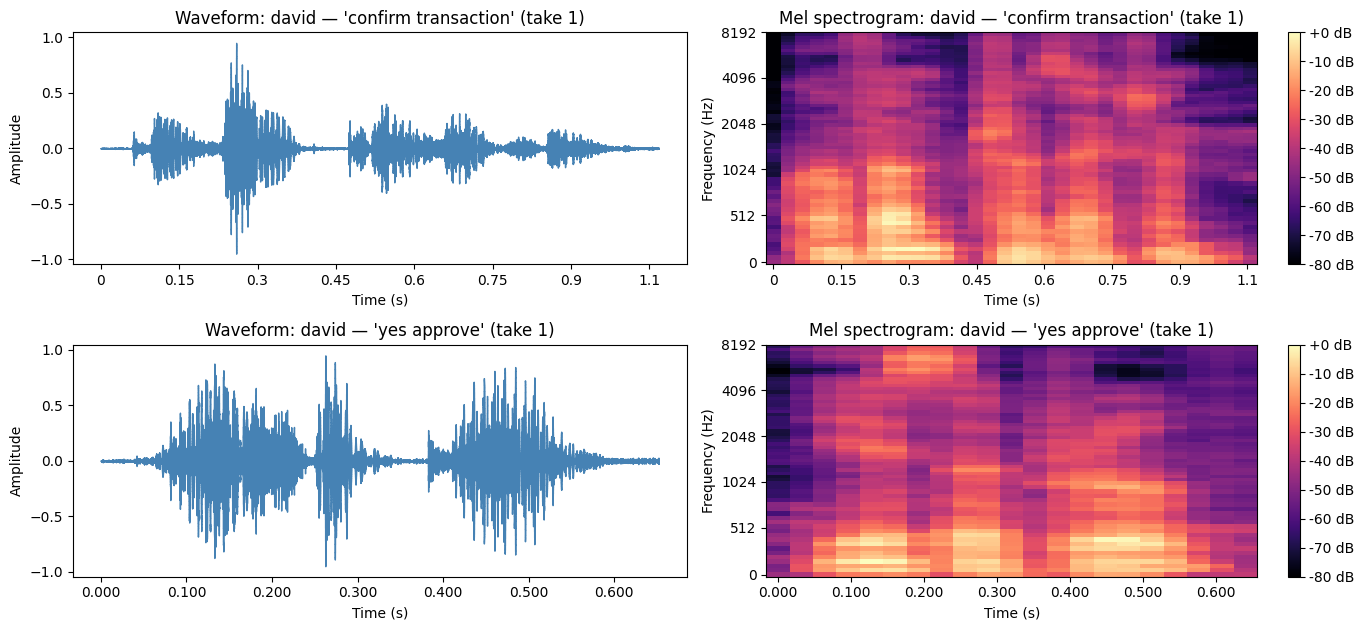

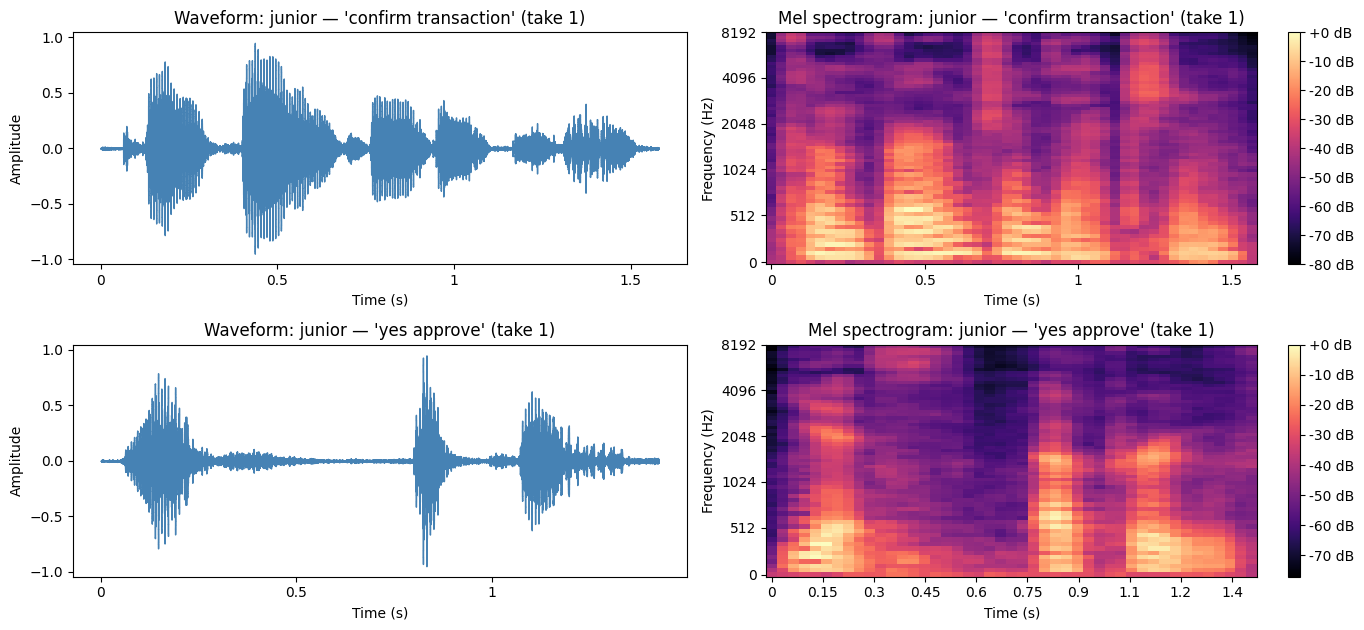

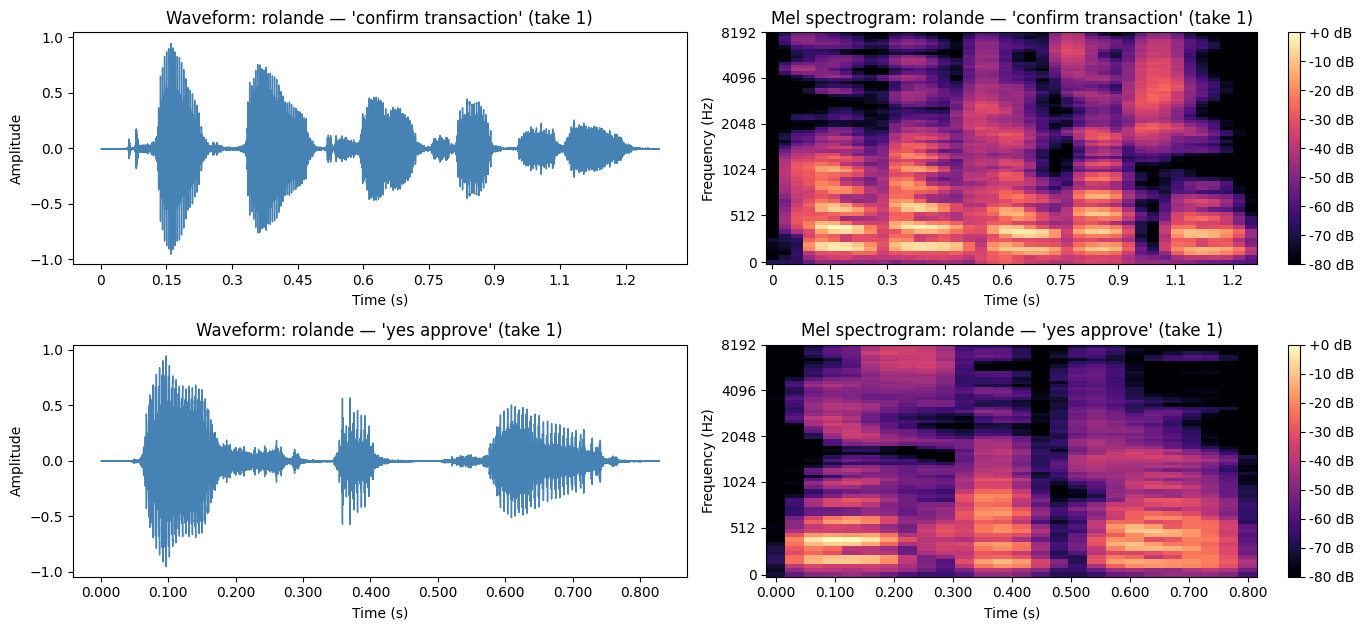

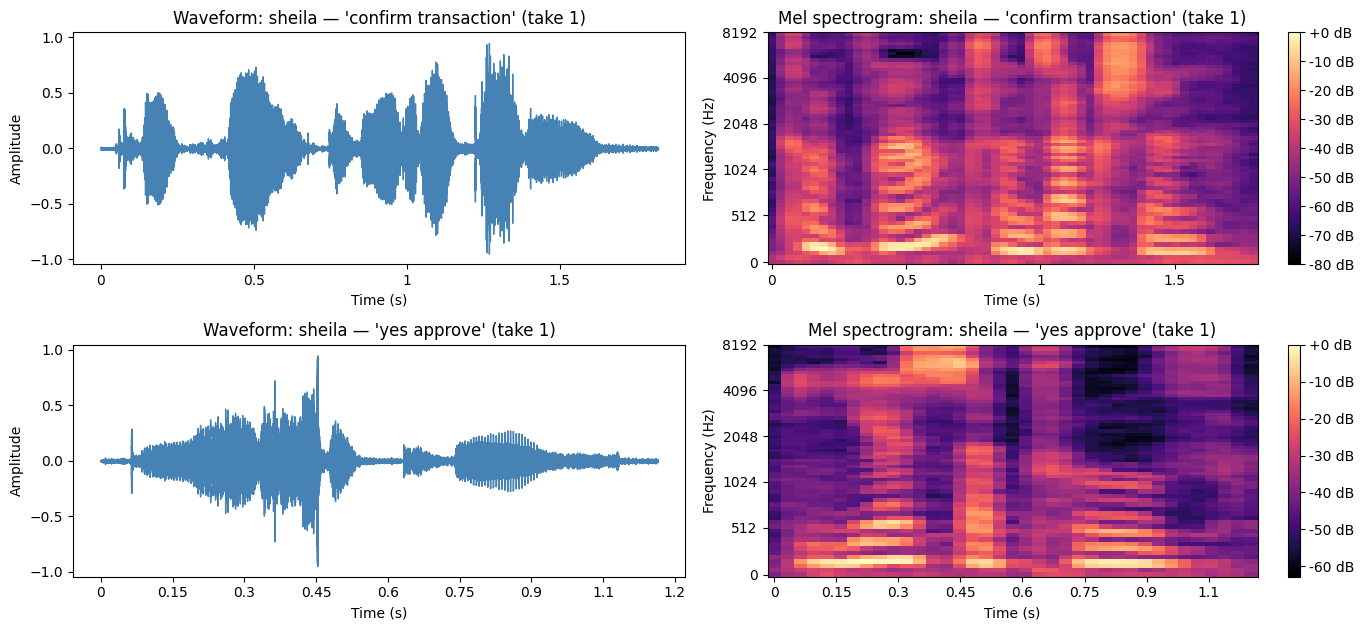

In [7]:
def plot_member(member):
    rows = inventory[inventory.member == member].reset_index(drop=True)
    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 3.2 * len(rows)), squeeze=False)
    for i, r in rows.iterrows():
        y, _ = librosa.load(CLEAN_DIR / r.clean_file, sr=SR)
        title = f"{member} — '{r.phrase.replace('_', ' ')}' (take {r['take']})"

        librosa.display.waveshow(y, sr=SR, ax=axes[i, 0], color="steelblue")
        axes[i, 0].set(title=f"Waveform: {title}", xlabel="Time (s)", ylabel="Amplitude")

        S_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64), ref=np.max)
        img = librosa.display.specshow(S_db, sr=SR, x_axis="time", y_axis="mel", ax=axes[i, 1], cmap="magma")
        axes[i, 1].set(title=f"Mel spectrogram: {title}", xlabel="Time (s)", ylabel="Frequency (Hz)")
        fig.colorbar(img, ax=axes[i, 1], format="%+2.0f dB")
    plt.tight_layout()
    fig.savefig(PLOT_DIR / f"{member}_waveform_spectrogram.png", dpi=120)
    plt.show()

for member in inventory.member.unique():
    plot_member(member)

Pitch (estimated with the pYIN algorithm), spectral centroid and energy per recording and per member:

In [8]:
# Average pitch, spectral centroid (brightness) and RMS energy
summary = []
for _, r in inventory.iterrows():
    y, _ = librosa.load(CLEAN_DIR / r.clean_file, sr=SR)
    f0, voiced, _ = librosa.pyin(y, fmin=60, fmax=400, sr=SR)
    summary.append({
        "member": r.member, "phrase": r.phrase,
        "duration_s": r.clean_duration_s,
        "avg_pitch_hz": round(float(np.nanmean(f0)), 1) if np.any(voiced) else np.nan,
        "spectral_centroid_hz": round(float(librosa.feature.spectral_centroid(y=y, sr=SR).mean()), 1),
        "rms_energy": r.rms_energy,
    })
voice_summary = pd.DataFrame(summary)
display(voice_summary)
display(voice_summary.groupby("member")[["duration_s", "avg_pitch_hz", "spectral_centroid_hz"]].mean().round(1))

,member,phrase,duration_s,avg_pitch_hz,spectral_centroid_hz,rms_energy
0,david,confirm_transaction,1.07,83.0,1494.6,0.1024
1,david,yes_approve,0.65,94.4,1918.3,0.1948
2,junior,confirm_transaction,1.58,111.9,1473.6,0.1559
3,junior,yes_approve,1.43,89.8,1672.6,0.1089
4,rolande,confirm_transaction,1.28,199.3,1533.5,0.1419
5,rolande,yes_approve,0.83,190.2,1714.5,0.1647
6,sheila,confirm_transaction,1.82,191.1,2583.5,0.1574
7,sheila,yes_approve,1.16,177.3,3205.8,0.1022


,duration_s,avg_pitch_hz,spectral_centroid_hz
member,,,
david,0.9,88.7,1706.4
junior,1.5,100.8,1573.1
rolande,1.1,194.8,1624.0
sheila,1.5,184.2,2894.6


### Interpretation

**Waveforms.** Each burst in a waveform is a syllable, and the flat parts between them are pauses.
"Confirm transaction" shows 5–6 bursts (*con-firm trans-ac-tion*): Rolande's clip has six clearly separated bursts in 1.28 s.
"Yes, approve" shows 2–3 bursts (*yes / ap-prove*). Junior, for example, says "yes" at about 0.1–0.3 s, then pauses for about half a
second before "approve" at 0.8–1.3 s. Speaking rate differs clearly between members. For "Yes, approve", David is the fastest (0.65 s),
then Rolande (0.83 s), Sheila (1.16 s) and Junior (1.43 s, because of his long pause). For "Confirm transaction" the order is the same:
David 1.07 s, Rolande 1.28 s, Junior 1.58 s, Sheila 1.82 s.

**Spectrograms.** In every member's spectrogram most of the energy sits below about 1 kHz (the bright band at the bottom), where the
fundamental pitch and the first formants of the voice are. In vowels the energy forms **horizontal stripes**, which are the harmonics of
the voice. Their spacing depends on pitch: Rolande (≈ 195 Hz) and Sheila (≈ 184 Hz) have the highest average pitch, so their stripes are
widely spaced and easy to see (e.g. Sheila's "firm" at 0.4–0.6 s). Junior (≈ 101 Hz) and David (≈ 89 Hz) are much lower, so their stripes
are packed tightly together and blur into one bright band. The *s/sh* sounds in "yes" and "transaction" appear as bright
**vertical patches above 4 kHz with no stripes** (e.g. Sheila's "trans" at about 1.3 s), because fricatives are noise-like and not
pitched. Sheila's recordings have the most high-frequency energy (spectral centroid ≈ 2,900 Hz vs ≈ 1,550–1,700 Hz for the others),
which comes from stronger *s* sounds and a different phone microphone (.m4a vs .wav).

**Consistency.** Pitch is very similar across both phrases for David (83 vs 94 Hz), Rolande (199 vs 190 Hz) and Sheila (191 vs 177 Hz),
which is what makes voice features useful for identifying a speaker. Junior's pitch differs more (112 vs 90 Hz), probably because
"Yes, approve" is short with a long pause, so the pitch tracker had few voiced frames to work with.

**Quality.** The gaps between words are dark (about −60 to −80 dB), so background noise is low for all members. Several recordings
(both of Sheila's, plus David's and Junior's "Yes, approve") contained a short click from pressing the record/stop button. Before cleaning,
these clicks made Sheila's "Confirm transaction" 3.0 s long instead of 1.8 s and distorted her pitch estimate (130 Hz instead of ≈ 184 Hz).
The click-aware trimming removed them, so the features describe the voices and not the phones.

**Why this matters.** The same phrase produces a different pattern for each person (pitch, harmonic spacing, brightness, speaking rate)
but a similar pattern for the same person across both phrases. MFCCs summarise exactly this pattern, so they are the main input to the
voiceprint verification model. In the PCA plot Rolande forms a clearly separate cluster and Sheila's clips group together; David's and
Junior's overlap the most, so that is where the voice model is most likely to make mistakes. The unauthorized speaker falls in a gap
between the clusters, not inside any member's group.

## 3. Data augmentation

With only two recordings per member, there is too little data to train a model. Augmentation creates realistic variations of each
recording, simulating how the same person sounds on a different day, at a different pace or in a noisier place:

| Augmentation | What it simulates | Setting |
|---|---|---|
| Pitch shift | Natural changes in voice pitch (tiredness, excitement, a cold) | ±2 semitones |
| Time stretch | Speaking faster or slower, without changing pitch | ×0.85 and ×1.15 speed |
| Background noise | A noisy room or a lower-quality microphone | Gaussian noise at 20 dB SNR |

Each cleaned recording receives 5 augmented versions (3 techniques, two of them in both directions).

In [9]:
def pitch_shift(y, steps):
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=steps)

def time_stretch(y, rate):
    return librosa.effects.time_stretch(y, rate=rate)   # rate > 1 = faster

def add_noise(y, snr_db=20):
    signal_power = np.mean(y ** 2)
    noise_power = signal_power / (10 ** (snr_db / 10))
    return y + rng.normal(0, np.sqrt(noise_power), len(y))

AUGMENTATIONS = {
    "pitch_up":   lambda y: pitch_shift(y, +2),
    "pitch_down": lambda y: pitch_shift(y, -2),
    "stretch_slow": lambda y: time_stretch(y, 0.85),
    "stretch_fast": lambda y: time_stretch(y, 1.15),
    "noise":      lambda y: add_noise(y, 20),
}

aug_records = []
for _, r in inventory.iterrows():
    y, _ = librosa.load(CLEAN_DIR / r.clean_file, sr=SR)
    for aug_name, fn in AUGMENTATIONS.items():
        y_aug = fn(y)
        y_aug = 0.95 * y_aug / np.max(np.abs(y_aug))       # keep it in range
        out_name = f"{Path(r.clean_file).stem}_{aug_name}.wav"
        sf.write(AUG_DIR / out_name, y_aug, SR)
        aug_records.append({"member": r.member, "phrase": r.phrase, "take": r['take'],
                            "augmentation": aug_name, "file": out_name})

aug_df = pd.DataFrame(aug_records)
print(f"Created {len(aug_df)} augmented files in {AUG_DIR}/ "
      f"({len(inventory)} originals × {len(AUGMENTATIONS)} augmentations)")
aug_df.head(10)

Created 40 augmented files in audio/augmented/ (8 originals × 5 augmentations)


,member,phrase,take,augmentation,file
0,david,confirm_transaction,1,pitch_up,david_confirm_transaction_1_pitch_up.wav
1,david,confirm_transaction,1,pitch_down,david_confirm_transaction_1_pitch_down.wav
2,david,confirm_transaction,1,stretch_slow,david_confirm_transaction_1_stretch_slow.wav
3,david,confirm_transaction,1,stretch_fast,david_confirm_transaction_1_stretch_fast.wav
4,david,confirm_transaction,1,noise,david_confirm_transaction_1_noise.wav
5,david,yes_approve,1,pitch_up,david_yes_approve_1_pitch_up.wav
6,david,yes_approve,1,pitch_down,david_yes_approve_1_pitch_down.wav
7,david,yes_approve,1,stretch_slow,david_yes_approve_1_stretch_slow.wav
8,david,yes_approve,1,stretch_fast,david_yes_approve_1_stretch_fast.wav
9,david,yes_approve,1,noise,david_yes_approve_1_noise.wav


Comparison of one original recording with its five augmented versions:

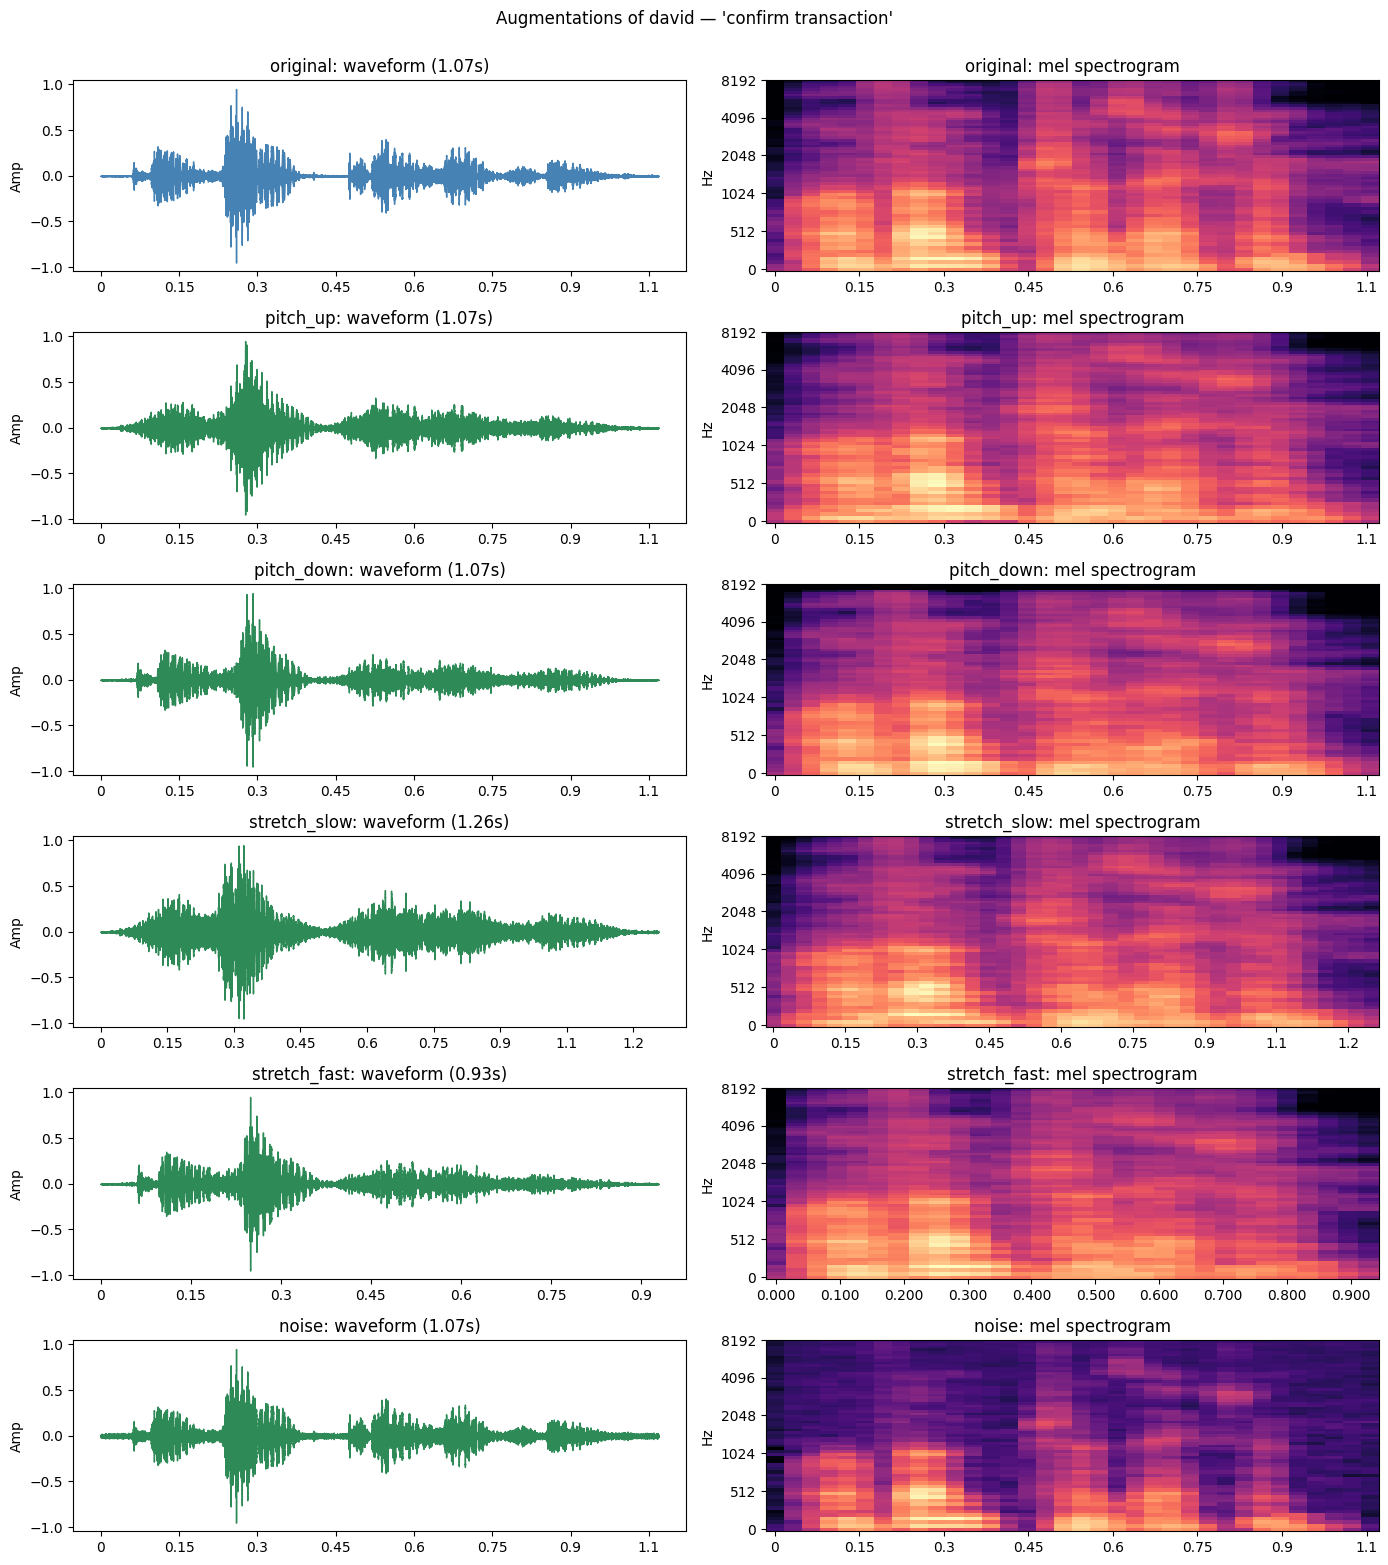

original


pitch_up


pitch_down


stretch_slow


stretch_fast


noise


In [10]:
example = inventory.iloc[0]
versions = [("original", CLEAN_DIR / example.clean_file)] + [
    (a, AUG_DIR / f"{Path(example.clean_file).stem}_{a}.wav") for a in AUGMENTATIONS]

fig, axes = plt.subplots(len(versions), 2, figsize=(14, 2.6 * len(versions)))
for i, (name, path) in enumerate(versions):
    y, _ = librosa.load(path, sr=SR)
    librosa.display.waveshow(y, sr=SR, ax=axes[i, 0], color="seagreen" if name != "original" else "steelblue")
    axes[i, 0].set(title=f"{name}: waveform ({len(y)/SR:.2f}s)", xlabel="", ylabel="Amp")
    S_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64), ref=np.max)
    librosa.display.specshow(S_db, sr=SR, x_axis="time", y_axis="mel", ax=axes[i, 1], cmap="magma")
    axes[i, 1].set(title=f"{name}: mel spectrogram", xlabel="", ylabel="Hz")
plt.suptitle(f"Augmentations of {example.member} — '{example.phrase.replace('_', ' ')}'", y=1.0)
plt.tight_layout()
fig.savefig(PLOT_DIR / "augmentation_examples.png", dpi=120)
plt.show()

for name, path in versions:
    print(name); display(Audio(str(path), rate=SR))

Pitch shifting moves the harmonic stripes up or down. Time stretching makes the clip shorter or longer while the stripes stay at the same
height. Added noise fills the dark gaps between words with a faint speckle across all frequencies. In every version the phrase remains
clearly recognisable, so the label (the speaker) is still correct.

## 4. Feature extraction

A classifier cannot use raw audio directly, so each clip is summarised as one row of numbers. Features are computed on short frames,
and the **mean and standard deviation across frames** are kept so that clips of different lengths give rows of the same size.

| Feature | What it measures | Columns |
|---|---|---|
| MFCCs (13) | Shape of the vocal tract; the main voiceprint feature | `mfcc_1_mean` … `mfcc_13_mean`, `mfcc_1_std` … |
| Delta MFCCs | How the MFCCs change over time (speaking style) | `delta_mfcc_1_mean` … |
| Spectral roll-off | Frequency below which 85% of the energy lies | `rolloff_mean`, `rolloff_std` |
| RMS energy | Loudness | `rms_mean`, `rms_std` |
| Spectral centroid | Centre of mass of the spectrum (brightness) | `centroid_mean`, `centroid_std` |
| Spectral bandwidth | Spread of frequencies around the centroid | `bandwidth_mean`, `bandwidth_std` |
| Zero-crossing rate | Noisiness, high for *s/sh* sounds | `zcr_mean`, `zcr_std` |
| Duration | Length of the clip | `duration_s` |

In [11]:
def extract_features(y):
    feats = {"duration_s": len(y) / SR}

    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC)
    delta = librosa.feature.delta(mfcc)
    for i in range(N_MFCC):
        feats[f"mfcc_{i+1}_mean"] = mfcc[i].mean()
        feats[f"mfcc_{i+1}_std"] = mfcc[i].std()
    for i in range(N_MFCC):
        feats[f"delta_mfcc_{i+1}_mean"] = delta[i].mean()

    spectral = {
        "rolloff":   librosa.feature.spectral_rolloff(y=y, sr=SR, roll_percent=0.85)[0],
        "rms":       librosa.feature.rms(y=y)[0],
        "centroid":  librosa.feature.spectral_centroid(y=y, sr=SR)[0],
        "bandwidth": librosa.feature.spectral_bandwidth(y=y, sr=SR)[0],
        "zcr":       librosa.feature.zero_crossing_rate(y)[0],
    }
    for name, values in spectral.items():
        feats[f"{name}_mean"] = values.mean()
        feats[f"{name}_std"] = values.std()
    return feats


rows = []
# originals
for _, r in inventory.iterrows():
    y, _ = librosa.load(CLEAN_DIR / r.clean_file, sr=SR)
    rows.append({"file": r.clean_file, "member": r.member, "phrase": r.phrase,
                 "take": r['take'], "augmentation": "original", **extract_features(y)})
# augmented
for _, r in aug_df.iterrows():
    y, _ = librosa.load(AUG_DIR / r.file, sr=SR)
    rows.append({"file": r.file, "member": r.member, "phrase": r.phrase,
                 "take": r['take'], "augmentation": r.augmentation, **extract_features(y)})

audio_features = pd.DataFrame(rows)
audio_features["take"] = audio_features["take"].astype(int)
num_cols = [c for c in audio_features.select_dtypes("number").columns if c != "take"]
audio_features[num_cols] = audio_features[num_cols].round(5)
audio_features.to_csv(FEATURES_CSV, index=False)

print(f"Saved {FEATURES_CSV}  →  {audio_features.shape[0]} rows × {audio_features.shape[1]} columns")
audio_features.head()

Saved audio_features.csv  →  48 rows × 55 columns


,file,member,phrase,take,augmentation,duration_s,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,rolloff_mean,rolloff_std,rms_mean,rms_std,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,zcr_mean,zcr_std
0,david_confirm_transaction_1.wav,david,confirm_transaction,1,original,1.068,-199.933853,110.831032,107.106750,42.446281,...,2993.79596,1488.34461,0.08496,0.05546,1494.63494,700.03091,1646.27790,388.60264,0.09781,0.04915
1,david_yes_approve_1.wav,david,yes_approve,1,original,0.652,-140.755264,96.854233,97.166039,54.700760,...,3933.40774,2150.39159,0.17047,0.08803,1918.32479,1180.69067,1888.47540,612.70922,0.14283,0.12598
2,junior_confirm_transaction_1.wav,junior,confirm_transaction,1,original,1.580,-178.514359,66.290916,116.945358,56.559319,...,2837.81250,2164.49881,0.13294,0.07954,1473.61863,1029.94021,1602.66066,559.70098,0.11472,0.09612
3,junior_yes_approve_1.wav,junior,yes_approve,1,original,1.428,-228.721695,89.228271,111.404778,45.258228,...,3531.59722,2076.81921,0.08028,0.07286,1672.64416,975.43744,1809.39429,656.58898,0.11464,0.08617
4,rolande_confirm_transaction_1.wav,rolande,confirm_transaction,1,original,1.276,-258.433167,107.806892,100.533829,87.032494,...,2657.22656,2161.55808,0.12232,0.07144,1533.46123,1189.52725,1442.57782,598.95476,0.12968,0.09710


### Validation of `audio_features.csv`

In [12]:
check = pd.read_csv(FEATURES_CSV)
print("Shape:", check.shape)
print("Missing values:", int(check.isna().sum().sum()))
print("Duplicate rows:", int(check.duplicated().sum()))
print("\nRows per member:")
display(check.groupby(["member", "augmentation"]).size().unstack(fill_value=0))
print("Required features present:",
      all(c in check.columns for c in ["mfcc_1_mean", "rolloff_mean", "rms_mean"]))
display(check.describe().T.head(12))

Shape: (48, 55)
Missing values: 0
Duplicate rows: 0

Rows per member:


augmentation,noise,original,pitch_down,pitch_up,stretch_fast,stretch_slow
member,,,,,,
david,2,2,2,2,2,2
junior,2,2,2,2,2,2
rolande,2,2,2,2,2,2
sheila,2,2,2,2,2,2


Required features present: True


,count,mean,std,min,25%,50%,75%,max
take,48.0,1.000000,0.000000,1.00000,1.000000,1.000000,1.000000,1.00000
duration_s,48.0,1.236417,0.384547,0.56694,0.962762,1.249125,1.520892,2.14119
mfcc_1_mean,48.0,-173.430307,49.100879,-261.40897,-208.554908,-157.405725,-136.071310,-80.30348
mfcc_1_std,48.0,76.197643,20.078332,35.47148,62.169988,80.487580,90.027838,110.83103
mfcc_2_mean,48.0,86.570893,32.270965,19.12261,54.392792,100.616375,112.524718,128.98618
mfcc_2_std,48.0,49.303983,11.750492,33.63950,40.793318,48.114090,55.092505,87.03249
mfcc_3_mean,48.0,22.487105,10.422009,0.01891,15.086232,23.381170,31.425832,40.08673
mfcc_3_std,48.0,27.832673,8.077396,15.07016,21.988447,26.756000,33.583678,47.54914
mfcc_4_mean,48.0,11.916575,12.511169,-7.87320,0.812480,12.470995,20.495500,44.15263
mfcc_4_std,48.0,26.334513,13.700770,11.98725,17.018197,21.620065,27.442203,62.28166


### Speaker separability
The 50 features are standardised and reduced to two dimensions with PCA. If each member's clips form their own cluster, the features
carry speaker identity and are suitable for the voiceprint verification model.

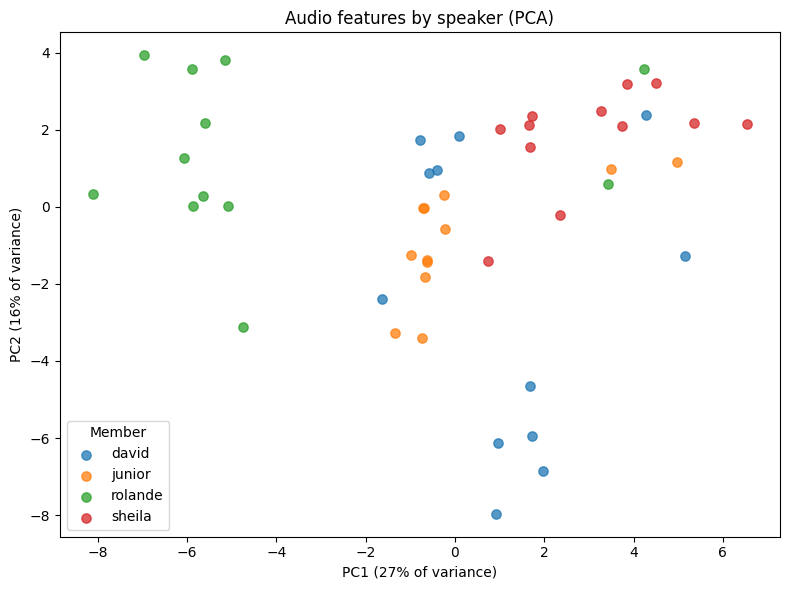

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

feature_cols = [c for c in check.columns if c not in ["file", "member", "phrase", "take", "augmentation"]]
X = StandardScaler().fit_transform(check[feature_cols])
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
for member in check.member.unique():
    mask = check.member == member
    ax.scatter(Z[mask, 0], Z[mask, 1], label=member, alpha=0.75, s=45)
ax.set(title="Audio features by speaker (PCA)",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.legend(title="Member")
plt.tight_layout()
fig.savefig(PLOT_DIR / "audio_features_pca.png", dpi=120)
plt.show()

## 5. Unauthorized voice

The recording from a person outside the group is **not** included in `audio_features.csv`, so that the voice model never sees it during
training and it can act as a genuinely unknown intruder in the system demonstration. It goes through exactly the same cleaning and
feature extraction and is saved separately in `unauthorized_audio_features.csv`.

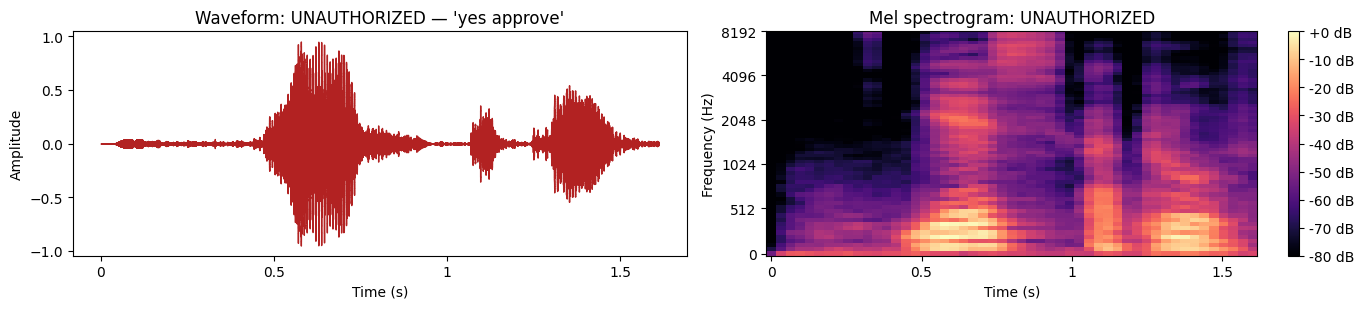

Saved unauthorized_audio_features.csv  →  1 row(s) × 55 columns


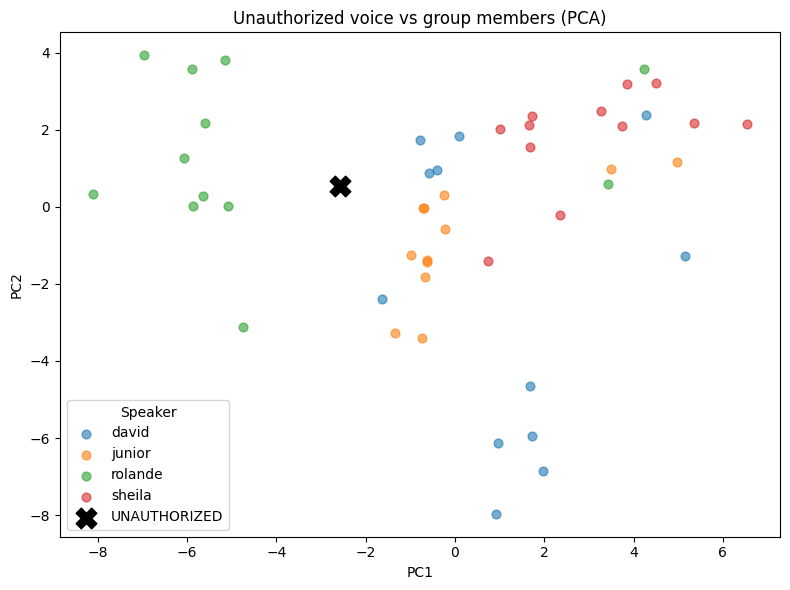

In [14]:
UNAUTH_DIR = Path("audio/unauthorized")
UNAUTH_CLEAN = UNAUTH_DIR / "clean"
UNAUTH_CLEAN.mkdir(parents=True, exist_ok=True)

# move the outsider's files out of audio/raw
for p in list(RAW_DIR.iterdir()):
    if p.is_file() and p.name.lower().startswith(UNAUTHORIZED_PREFIXES):
        shutil.move(str(p), str(UNAUTH_DIR / p.name))

unauth_rows = []
for p in sorted(UNAUTH_DIR.iterdir()):
    if not p.is_file() or p.suffix.lower() not in AUDIO_EXTS:
        continue
    _, phrase, take = parse_name(p)
    tmp = UNAUTH_DIR / "_tmp.wav"
    to_wav_16k_mono(p, tmp)
    y_raw, _ = librosa.load(tmp, sr=SR, mono=True)
    tmp.unlink()
    y = clean_audio(y_raw)
    out_name = f"unknown_{phrase}_{take}.wav"
    sf.write(UNAUTH_CLEAN / out_name, y, SR)
    unauth_rows.append({"file": out_name, "member": "unknown", "phrase": phrase, "take": take,
                        "augmentation": "original", **extract_features(y)})

    # waveform + spectrogram, same as for the members
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
    librosa.display.waveshow(y, sr=SR, ax=axes[0], color="firebrick")
    axes[0].set(title=f"Waveform: UNAUTHORIZED — '{phrase.replace('_', ' ')}'", xlabel="Time (s)", ylabel="Amplitude")
    S_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64), ref=np.max)
    img = librosa.display.specshow(S_db, sr=SR, x_axis="time", y_axis="mel", ax=axes[1], cmap="magma")
    axes[1].set(title="Mel spectrogram: UNAUTHORIZED", xlabel="Time (s)", ylabel="Frequency (Hz)")
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
    plt.tight_layout()
    fig.savefig(PLOT_DIR / f"unauthorized_{phrase}_waveform_spectrogram.png", dpi=120)
    plt.show()
    display(Audio(str(UNAUTH_CLEAN / out_name), rate=SR))

if unauth_rows:
    unauth_df = pd.DataFrame(unauth_rows)
    unauth_df["take"] = unauth_df["take"].astype(int)
    unauth_df.to_csv("unauthorized_audio_features.csv", index=False)
    print(f"Saved unauthorized_audio_features.csv  →  {unauth_df.shape[0]} row(s) × {unauth_df.shape[1]} columns")

    # where does the outsider land compared with the group members?
    scaler = StandardScaler().fit(check[feature_cols])
    pca_u = PCA(n_components=2, random_state=SEED).fit(scaler.transform(check[feature_cols]))
    Zm = pca_u.transform(scaler.transform(check[feature_cols]))
    Zu = pca_u.transform(scaler.transform(unauth_df[feature_cols]))
    fig, ax = plt.subplots(figsize=(8, 6))
    for member in check.member.unique():
        mask = check.member == member
        ax.scatter(Zm[mask, 0], Zm[mask, 1], label=member, alpha=0.6, s=40)
    ax.scatter(Zu[:, 0], Zu[:, 1], marker="X", s=220, c="black", label="UNAUTHORIZED")
    ax.set(title="Unauthorized voice vs group members (PCA)", xlabel="PC1", ylabel="PC2")
    ax.legend(title="Speaker")
    plt.tight_layout()
    fig.savefig(PLOT_DIR / "unauthorized_vs_members_pca.png", dpi=120)
    plt.show()
else:
    print("No unauthorized recording found. Put a file named unknown_yes_approve.<ext> in audio/raw/")

## Summary

* **Data collected:** 4 members (David, Junior, Rolande, Sheila) × 2 phrases ("Yes, approve", "Confirm transaction") = 8 recordings
  from different phones (.wav and .m4a). All were converted to 16 kHz mono WAV, trimmed of silence and phone-button clicks, and
  peak-normalised. A quality check confirmed both phrases for every member and no clipping.
* **Visualisation:** waveform and mel spectrogram plotted for every member (`plots/audio/`). Members differ clearly in pitch
  (Rolande ≈ 195 Hz, Sheila ≈ 184 Hz, Junior ≈ 101 Hz, David ≈ 89 Hz), visible as differently spaced harmonic stripes, and in
  speaking rate ("Yes, approve" ranges from 0.65 s for David to 1.43 s for Junior).
* **Augmentation:** 3 techniques (pitch shift ±2 semitones, time stretch ×0.85/×1.15, Gaussian noise at 20 dB SNR), giving
  5 augmented versions per recording → 8 originals + 40 augmented = **48 clips**.
* **Features:** 13 MFCCs (mean + std), 13 delta-MFCC means, spectral roll-off, RMS energy, spectral centroid, bandwidth,
  zero-crossing rate (mean + std each) and duration → **50 numeric features per clip**, saved in `audio_features.csv`
  (48 rows, no missing values or duplicates) with `member` as the label for the voiceprint verification model.
* **Unauthorized sample:** one "Yes, approve" recording from a person outside the group (Semana), processed the same way but kept out
  of the training data, saved in `unauthorized_audio_features.csv` for the Task 6 "access denied" demo. In feature space it falls
  outside every member's cluster.

**Output files:** `audio_features.csv`, `unauthorized_audio_features.csv`, `audio/clean/`, `audio/augmented/`,
`audio/unauthorized/clean/`, `plots/audio/*.png`.